# NextBuy - From Raw Data to Smart Decisions

## Exploratory Data Analysis & Predictive Modeling on Grocery Orders

This notebook analyzes millions of grocery orders to extract actionable business insights and build predictive models.

### Table of Contents
1. **Setup & Data Loading** - Import libraries, load and merge datasets
2. **Data Cleaning & Preprocessing** - Handle missing values, data types, feature engineering
3. **Exploratory Data Analysis** - 8 business insight questions answered with visualizations
4. **Predictive Modeling** - 2 ML models built, trained, evaluated and compared
5. **Conclusion** - Key takeaways and recommendations

---

## 1. Setup & Data Loading

In [ ]:
# Install dependencies if needed
# !pip install pandas numpy matplotlib seaborn scikit-learn xgboost

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

import warnings
warnings.filterwarnings('ignore')

# Plot style
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100

print('Libraries loaded successfully.')

Libraries loaded successfully.


### 1.1 Loading the Datasets

We have 5 CSV files:
- **orders.csv** - Order metadata (user, day of week, hour, days since prior order)
- **order_products.csv** - Which products are in each order
- **products.csv** - Product names and categories
- **aisles.csv** - Aisle names
- **departments.csv** - Department names

In [ ]:
orders = pd.read_csv('datasets/orders.csv')
order_products = pd.read_csv('datasets/order_products.csv')
products = pd.read_csv('datasets/products.csv')
aisles = pd.read_csv('datasets/aisles.csv')
departments = pd.read_csv('datasets/departments.csv')

print(f'orders:          {orders.shape[0]:>10,} rows x {orders.shape[1]} cols')
print(f'order_products:  {order_products.shape[0]:>10,} rows x {order_products.shape[1]} cols')
print(f'products:        {products.shape[0]:>10,} rows x {products.shape[1]} cols')
print(f'aisles:          {aisles.shape[0]:>10,} rows x {aisles.shape[1]} cols')
print(f'departments:     {departments.shape[0]:>10,} rows x {departments.shape[1]} cols')

orders:           1,444,444 rows x 6 cols
order_products:  13,692,886 rows x 4 cols
products:            49,688 rows x 4 cols
aisles:                 134 rows x 2 cols
departments:             21 rows x 2 cols


In [ ]:
print('=== orders ===')
display(orders.head())
print('\n=== order_products ===')
display(order_products.head())
print('\n=== products ===')
display(products.head())

=== orders ===


,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1.0,1.0,2.0,8.0,NaN
1,2398795,1.0,2.0,3.0,7.0,15.0
2,473747,1.0,3.0,3.0,12.0,21.0
3,2254736,1.0,4.0,4.0,7.0,29.0
4,431534,1.0,5.0,4.0,15.0,28.0



=== order_products ===


,order_id,product_id,add_to_cart_order,reordered
0,2,33120.0,1.0,1.0
1,2,28985.0,2.0,1.0
2,2,9327.0,3.0,0.0
3,2,45918.0,4.0,1.0
4,2,30035.0,5.0,0.0



=== products ===


,product_id,product_name,aisle_id,department_id
0,1,Chocolate Sandwich Cookies,61,19
1,2,All-Seasons Salt,104,13
2,3,Robust Golden Unsweetened Oolong Tea,94,7
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1
4,5,Green Chile Anytime Sauce,5,13


## 2. Data Cleaning & Preprocessing

In [ ]:
print('Missing values per dataset:\n')
for name, df in [('orders', orders), ('order_products', order_products),
                  ('products', products), ('aisles', aisles), ('departments', departments)]:
    missing = df.isnull().sum()
    missing = missing[missing > 0]
    if len(missing) > 0:
        print(f'{name}:')
        for col, cnt in missing.items():
            print(f'  {col}: {cnt:,} ({cnt/len(df)*100:.1f}%)')
    else:
        print(f'{name}: no missing values')

Missing values per dataset:

orders:
  user_id: 31 (0.0%)
  order_number: 23 (0.0%)
  order_dow: 22 (0.0%)
  order_hour_of_day: 23 (0.0%)
  days_since_prior_order: 86,909 (6.0%)
order_products:
  product_id: 449 (0.0%)
  add_to_cart_order: 446 (0.0%)
  reordered: 449 (0.0%)
products: no missing values
aisles: no missing values
departments: no missing values


`days_since_prior_order` is NaN for first-time orders (`order_number == 1`), which is expected. We keep these NaN values as they carry meaningful information.

In [ ]:
# Verify that NaN days_since_prior_order corresponds to first orders
first_orders = orders[orders['days_since_prior_order'].isnull()]
print(f'All NaN days_since_prior_order have order_number == 1: '
      f'{(first_orders["order_number"] == 1).all()}')

print(f'\nData types:')
display(orders.dtypes)

All NaN days_since_prior_order have order_number == 1: False

Data types:


order_id                    int64
user_id                   float64
order_number              float64
order_dow                 float64
order_hour_of_day         float64
days_since_prior_order    float64
dtype: object

In [ ]:
# Merge products with aisles and departments
products_full = (products
    .merge(aisles, on='aisle_id', how='left')
    .merge(departments, on='department_id', how='left'))

# Create full order-product dataset with all information
df = (order_products
    .merge(orders, on='order_id', how='left')
    .merge(products_full, on='product_id', how='left'))

print(f'Merged dataset: {df.shape[0]:,} rows x {df.shape[1]} cols')
display(df.head())

Merged dataset: 13,692,886 rows x 14 cols


,order_id,product_id,add_to_cart_order,reordered,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_name,aisle_id,department_id,aisle,department
0,2,33120.0,1.0,1.0,202279.0,3.0,5.0,9.0,8.0,Organic Egg Whites,86.0,16.0,eggs,dairy eggs
1,2,28985.0,2.0,1.0,202279.0,3.0,5.0,9.0,8.0,Michigan Organic Kale,83.0,4.0,fresh vegetables,produce
2,2,9327.0,3.0,0.0,202279.0,3.0,5.0,9.0,8.0,Garlic Powder,104.0,13.0,spices seasonings,pantry
3,2,45918.0,4.0,1.0,202279.0,3.0,5.0,9.0,8.0,Coconut Butter,19.0,13.0,oils vinegars,pantry
4,2,30035.0,5.0,0.0,202279.0,3.0,5.0,9.0,8.0,Natural Sweetener,17.0,13.0,baking ingredients,pantry


In [ ]:
# Feature: is the product organic?
df['is_organic'] = df['product_name'].str.contains('Organic', case=False, na=False).astype(int)

# Feature: time of day category
def time_of_day(hour):
    if 6 <= hour < 12:
        return 'Morning'
    elif 12 <= hour < 17:
        return 'Afternoon'
    elif 17 <= hour < 21:
        return 'Evening'
    else:
        return 'Night'

df['time_of_day'] = df['order_hour_of_day'].apply(time_of_day)

# Day names for readability
day_names = {0: 'Sunday', 1: 'Monday', 2: 'Tuesday', 3: 'Wednesday',
             4: 'Thursday', 5: 'Friday', 6: 'Saturday'}
df['day_name'] = df['order_dow'].map(day_names)

print(f'Organic products: {df["is_organic"].sum():,} items '
      f'({df["is_organic"].mean()*100:.1f}% of all ordered items)')
print(f'\nTime of day distribution:')
print(df['time_of_day'].value_counts())

Organic products: 4,331,665 items (31.6% of all ordered items)

Time of day distribution:


time_of_day
Afternoon    5557651
Morning      4590912
Evening      2519063
Night        1025260
Name: count, dtype: int64


---
## 3. Exploratory Data Analysis

We investigate **8 business insight questions**, each answered with appropriate statistics and visualizations.

### Business Questions:
1. Which products are the best sellers?
2. When and how do customers usually order? (day of week & hour patterns)
3. What is the proportion of organic food orders for fresh fruits and vegetables?
4. Which item do customers put in their cart first?
5. Which products have the highest probability of being reordered?
6. What are the main customer profiles?
7. Is there a relationship between time since last order and reorder probability?
8. Which aisle and department have the most/least products?

---

### Q1: Which products are the best sellers?

Understanding top-selling products helps optimize inventory, promotions, and shelf placement.

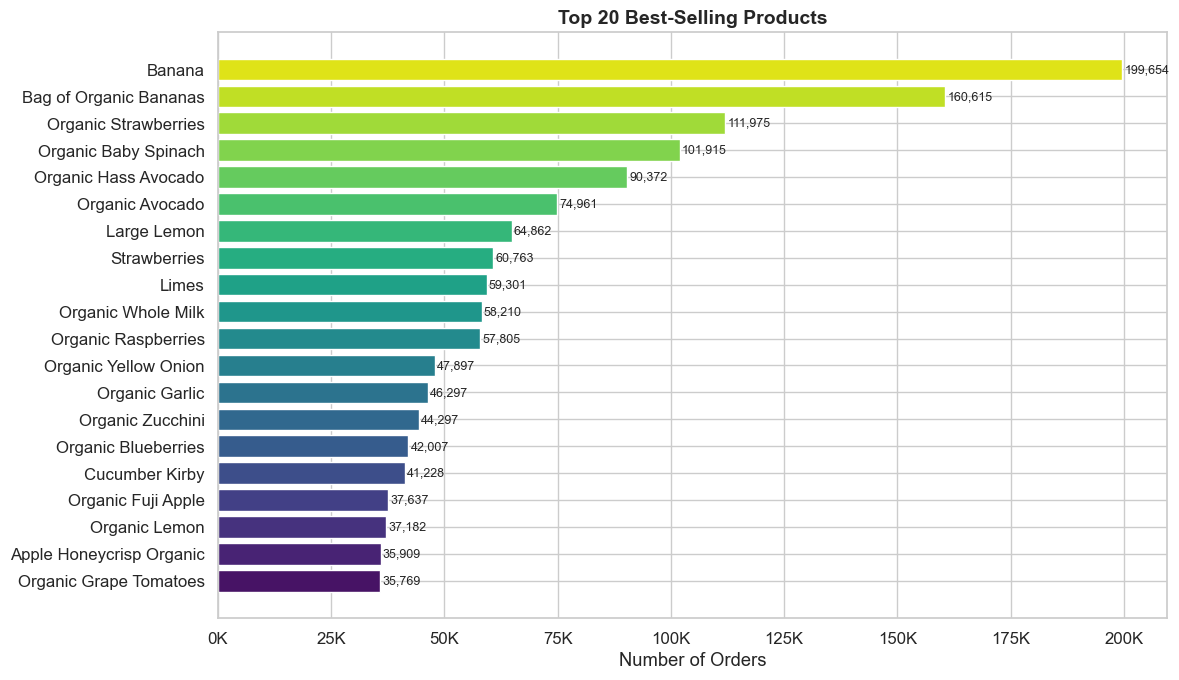


The #1 product is "Banana" with 199,654 orders.


In [ ]:
top_products = (df.groupby('product_name')
    .size()
    .reset_index(name='order_count')
    .sort_values('order_count', ascending=False)
    .head(20))

fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(top_products['product_name'][::-1], top_products['order_count'][::-1],
               color=sns.color_palette('viridis', 20))
ax.set_xlabel('Number of Orders')
ax.set_title('Top 20 Best-Selling Products', fontsize=14, fontweight='bold')
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x/1000:.0f}K'))

for bar in bars:
    width = bar.get_width()
    ax.text(width + 500, bar.get_y() + bar.get_height()/2,
            f'{width:,.0f}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

print(f'\nThe #1 product is "{top_products.iloc[0]["product_name"]}" '
      f'with {top_products.iloc[0]["order_count"]:,} orders.')

**Insight:** Fresh fruits (bananas, strawberries) dominate the top sellers. These are staple items that should always be well-stocked and prominently placed near store entrances.

---
### Q2: When and how do customers usually order?

Analyzing ordering patterns by day of week and hour of day helps optimize staffing, delivery logistics, and promotional timing.

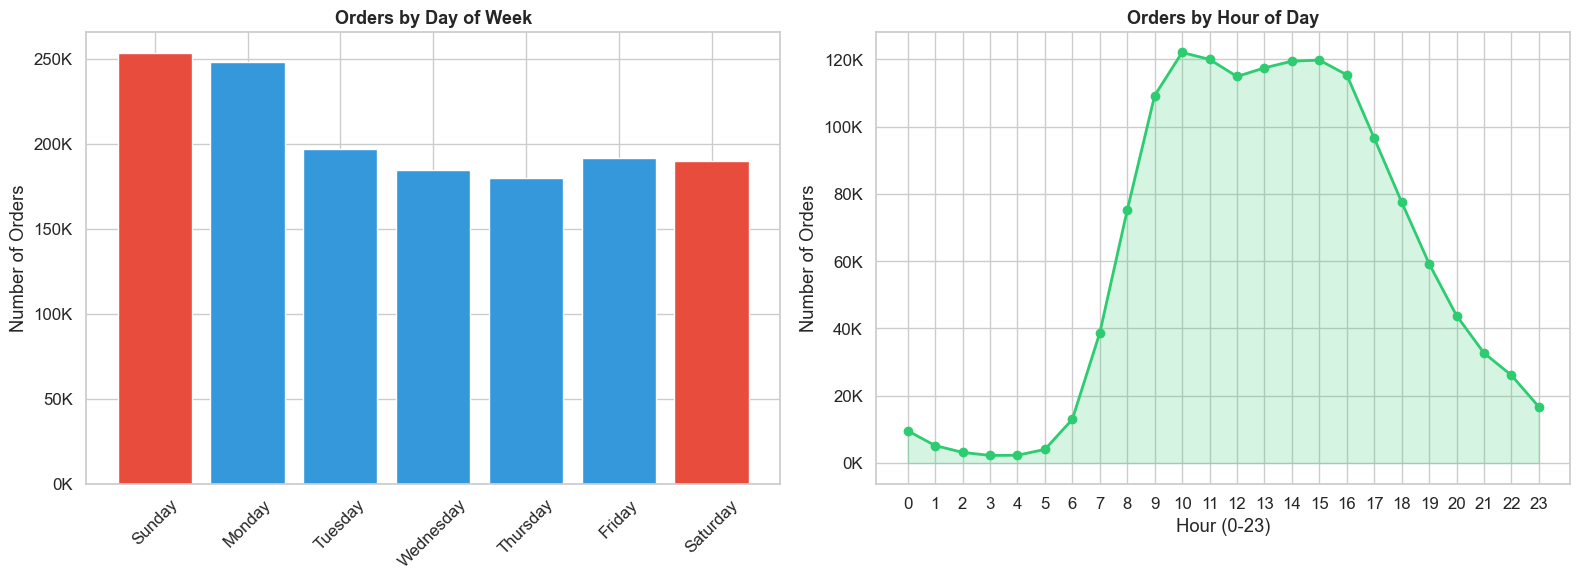

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Orders by day of week
dow_order = ['Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday']
orders_by_dow = orders['order_dow'].map(day_names).value_counts().reindex(dow_order)

colors_dow = ['#e74c3c' if d in ['Sunday', 'Saturday'] else '#3498db' for d in dow_order]
axes[0].bar(orders_by_dow.index, orders_by_dow.values, color=colors_dow)
axes[0].set_title('Orders by Day of Week', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Number of Orders')
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x/1000:.0f}K'))
axes[0].tick_params(axis='x', rotation=45)

# Orders by hour of day
orders_by_hour = orders['order_hour_of_day'].value_counts().sort_index()
axes[1].plot(orders_by_hour.index, orders_by_hour.values, 'o-', color='#2ecc71', linewidth=2)
axes[1].fill_between(orders_by_hour.index, orders_by_hour.values, alpha=0.2, color='#2ecc71')
axes[1].set_title('Orders by Hour of Day', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Hour (0-23)')
axes[1].set_ylabel('Number of Orders')
axes[1].yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x/1000:.0f}K'))
axes[1].set_xticks(range(0, 24))

plt.tight_layout()
plt.show()

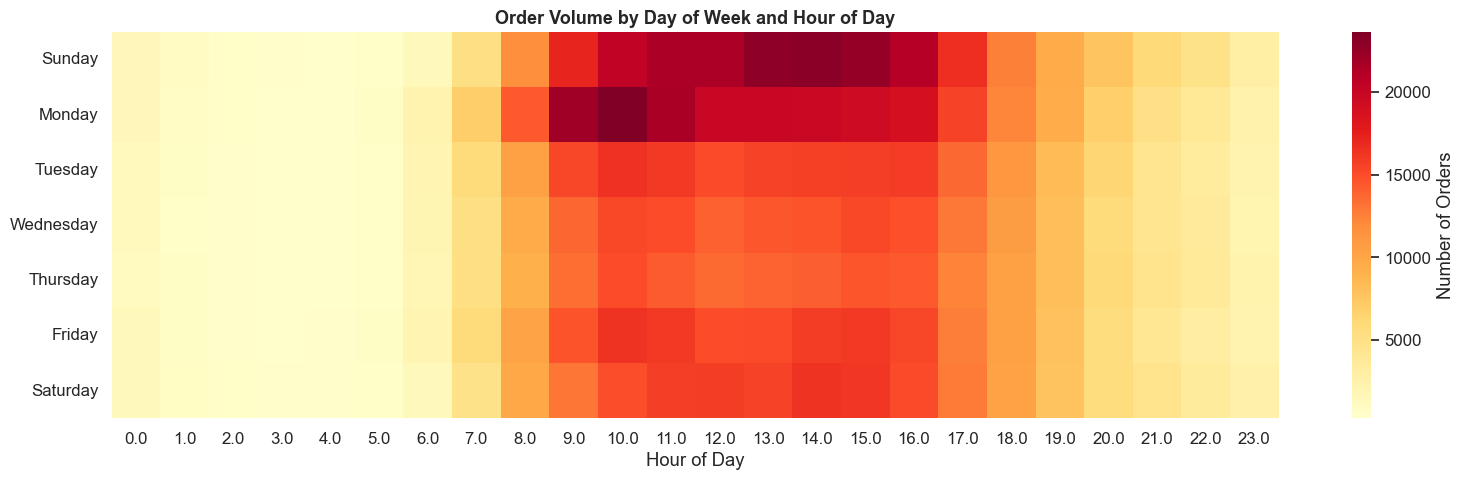

Peak ordering: Sunday & Monday, between 10am and 3pm.


In [ ]:
# Heatmap: orders by day x hour
heatmap_data = orders.groupby(['order_dow', 'order_hour_of_day']).size().unstack(fill_value=0)
heatmap_data.index = heatmap_data.index.map(day_names)
heatmap_data = heatmap_data.reindex(dow_order)

fig, ax = plt.subplots(figsize=(16, 5))
sns.heatmap(heatmap_data, cmap='YlOrRd', annot=False, fmt='d', ax=ax,
            cbar_kws={'label': 'Number of Orders'})
ax.set_title('Order Volume by Day of Week and Hour of Day', fontsize=13, fontweight='bold')
ax.set_xlabel('Hour of Day')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

print('Peak ordering: Sunday & Monday, between 10am and 3pm.')

**Insight:** Orders peak on **Sundays and Mondays** (weekend grocery runs), and during **late morning to early afternoon** (10am-3pm). Marketing campaigns should target Sunday mornings. Late-night orders (midnight-5am) are minimal, allowing for reduced staffing.

---
### Q3: What is the proportion of organic food orders for fresh fruits and vegetables?

Understanding organic demand in the produce section helps guide sourcing and pricing strategies.

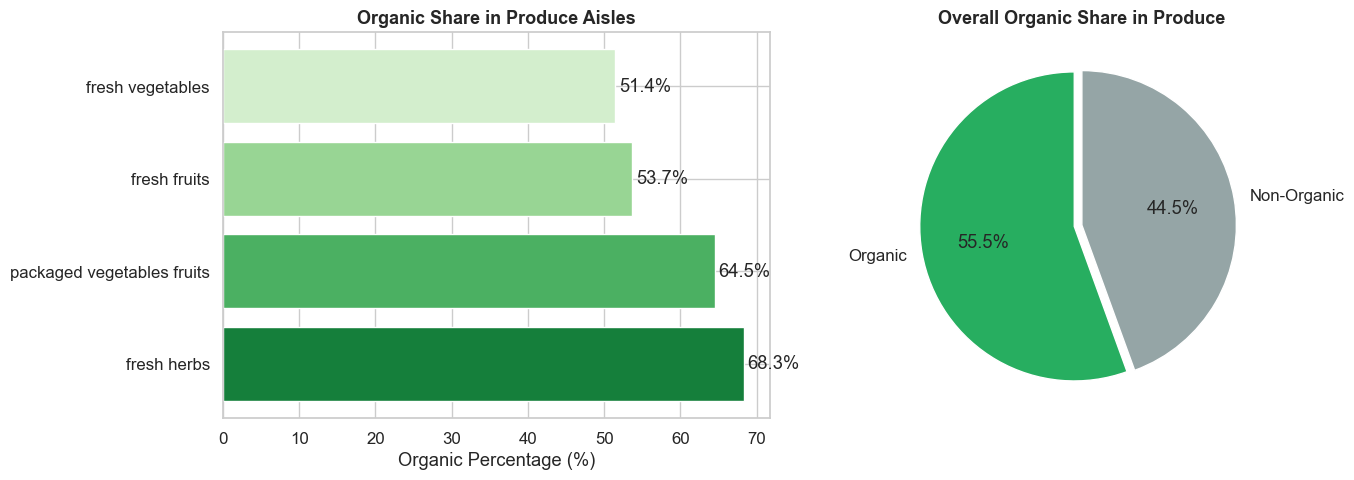

In [ ]:
produce_aisles = ['fresh fruits', 'fresh vegetables', 'packaged vegetables fruits',
                  'fresh herbs']
produce = df[df['aisle'].isin(produce_aisles)].copy()

organic_by_aisle = (produce.groupby('aisle')['is_organic']
    .agg(['sum', 'count'])
    .assign(organic_pct=lambda x: x['sum'] / x['count'] * 100)
    .sort_values('organic_pct', ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart: organic percentage by aisle
colors = sns.color_palette('Greens_r', len(organic_by_aisle))
axes[0].barh(organic_by_aisle.index, organic_by_aisle['organic_pct'], color=colors)
axes[0].set_xlabel('Organic Percentage (%)')
axes[0].set_title('Organic Share in Produce Aisles', fontsize=13, fontweight='bold')
for i, (_, row) in enumerate(organic_by_aisle.iterrows()):
    axes[0].text(row['organic_pct'] + 0.5, i, f"{row['organic_pct']:.1f}%", va='center')

# Pie chart: overall organic vs non-organic in produce
organic_total = produce['is_organic'].sum()
non_organic_total = len(produce) - organic_total
axes[1].pie([organic_total, non_organic_total],
            labels=['Organic', 'Non-Organic'],
            autopct='%1.1f%%', startangle=90,
            colors=['#27ae60', '#95a5a6'],
            explode=(0.05, 0))
axes[1].set_title('Overall Organic Share in Produce', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

**Insight:** A significant portion of produce orders are organic. Fresh herbs have the highest organic share. Stores should consider expanding organic produce sections and using this data to negotiate with organic suppliers for better margins.

---
### Q4: Which item do customers put in their cart first?

The first item added to the cart often represents the primary purchase intent. This insight can drive store layout and app UI decisions.

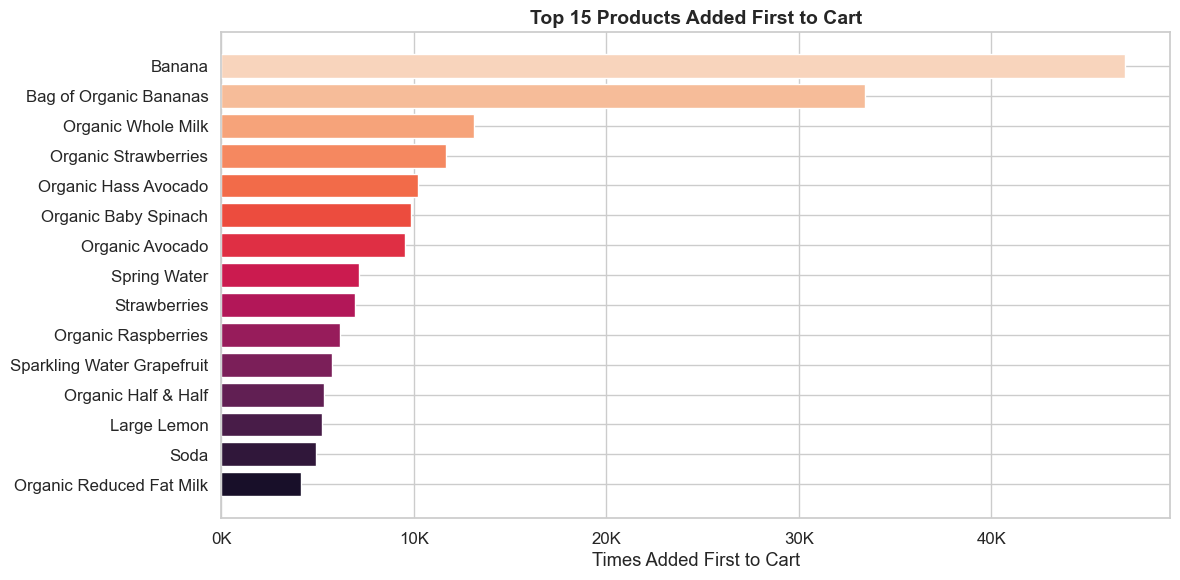

Top 5 departments for first-added items:
  produce: 28.0%
  dairy eggs: 20.3%
  beverages: 12.7%
  snacks: 7.0%
  frozen: 5.7%


In [ ]:
first_items = df[df['add_to_cart_order'] == 1]
first_item_counts = (first_items.groupby('product_name')
    .size()
    .reset_index(name='times_first')
    .sort_values('times_first', ascending=False)
    .head(15))

fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(first_item_counts['product_name'][::-1], first_item_counts['times_first'][::-1],
        color=sns.color_palette('rocket', 15))
ax.set_xlabel('Times Added First to Cart')
ax.set_title('Top 15 Products Added First to Cart', fontsize=14, fontweight='bold')
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x/1000:.0f}K'))
plt.tight_layout()
plt.show()

# First-item department distribution
first_dept = first_items['department'].value_counts(normalize=True).head(5) * 100
print('Top 5 departments for first-added items:')
for dept, pct in first_dept.items():
    print(f'  {dept}: {pct:.1f}%')

**Insight:** The most commonly first-added items are daily essentials (milk, bananas, produce). This reveals primary purchase intent and suggests these products should be placed at the entrance of the store or featured first in the app interface.

---
### Q5: Which products have the highest probability of being reordered?

High-reorder products represent staple household items. Identifying them helps build loyalty programs and auto-replenishment features.

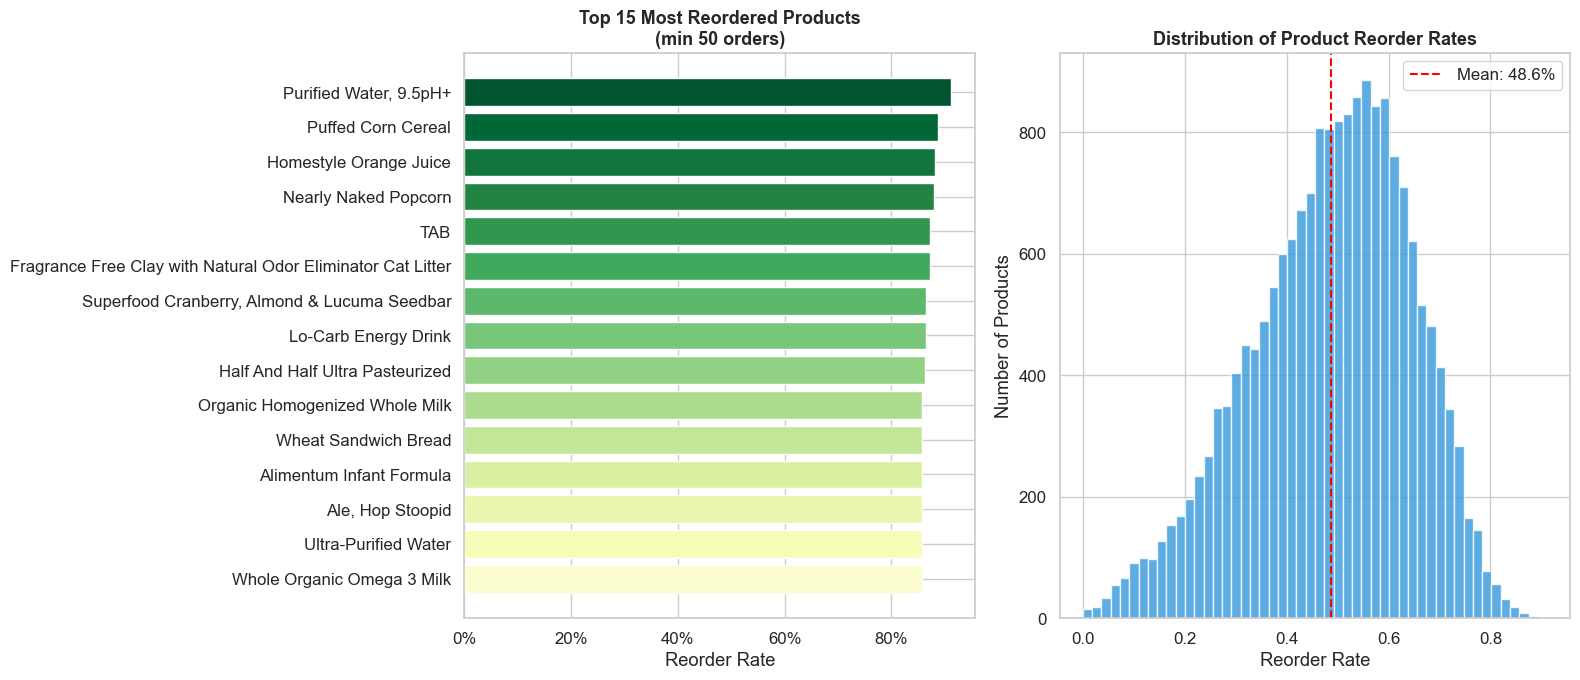

In [ ]:
MIN_ORDERS = 50  # Minimum orders to ensure statistical significance

reorder_rate = (df.groupby('product_name')
    .agg(total_orders=('reordered', 'count'),
         reorder_count=('reordered', 'sum'))
    .assign(reorder_rate=lambda x: x['reorder_count'] / x['total_orders'])
    .query(f'total_orders >= {MIN_ORDERS}')
    .sort_values('reorder_rate', ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Top 15 highest reorder rate
top_reorder = reorder_rate.head(15)
axes[0].barh(top_reorder.index[::-1], top_reorder['reorder_rate'][::-1],
             color=sns.color_palette('YlGn', 15))
axes[0].set_xlabel('Reorder Rate')
axes[0].set_title(f'Top 15 Most Reordered Products\n(min {MIN_ORDERS} orders)',
                  fontsize=13, fontweight='bold')
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:.0%}'))

# Reorder rate distribution
axes[1].hist(reorder_rate['reorder_rate'], bins=50, color='#3498db', edgecolor='white', alpha=0.8)
axes[1].axvline(reorder_rate['reorder_rate'].mean(), color='red', linestyle='--',
                label=f'Mean: {reorder_rate["reorder_rate"].mean():.1%}')
axes[1].set_xlabel('Reorder Rate')
axes[1].set_ylabel('Number of Products')
axes[1].set_title('Distribution of Product Reorder Rates', fontsize=13, fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

**Insight:** Products with the highest reorder rates are typically daily essentials like milk and produce. These items are ideal candidates for subscription/auto-replenishment services, and should always be in stock to maintain customer loyalty.

---
### Q6: What are the main customer profiles?

Segmenting customers by behavior (order frequency, cart size, time preferences) helps personalize marketing and optimize the shopping experience.

In [ ]:
# Build customer-level features
cart_sizes = df.groupby(['user_id', 'order_id']).size().reset_index(name='cart_size')

user_features = orders.groupby('user_id').agg(
    total_orders=('order_id', 'count'),
    avg_days_between_orders=('days_since_prior_order', 'mean'),
    avg_hour=('order_hour_of_day', 'mean'),
    favorite_dow=('order_dow', lambda x: x.mode().iloc[0] if len(x.mode()) > 0 else x.median())
).reset_index()

avg_cart = cart_sizes.groupby('user_id')['cart_size'].mean().reset_index(name='avg_cart_size')

reorder_user = df.groupby('user_id')['reordered'].mean().reset_index(name='reorder_ratio')

user_features = (user_features
    .merge(avg_cart, on='user_id')
    .merge(reorder_user, on='user_id'))

print(f'Customer features computed for {len(user_features):,} users')
display(user_features.describe().round(2))

Customer features computed for 197,362 users


,user_id,total_orders,avg_days_between_orders,avg_hour,favorite_dow,avg_cart_size,reorder_ratio
count,197362.00,197362.00,193604.00,197362.00,197361.00,197362.00,197362.00
mean,103130.19,7.30,15.15,13.58,2.03,9.97,0.45
std,59530.33,7.34,7.85,2.59,2.00,6.27,0.25
min,1.00,1.00,0.00,0.00,0.00,1.00,0.00
25%,51570.25,3.00,8.67,12.00,0.00,5.50,0.25
50%,103113.50,5.00,14.00,13.50,1.00,8.83,0.46
75%,154693.75,9.00,20.71,15.20,4.00,13.00,0.64
max,206209.00,58.00,30.00,23.00,6.00,81.00,1.00


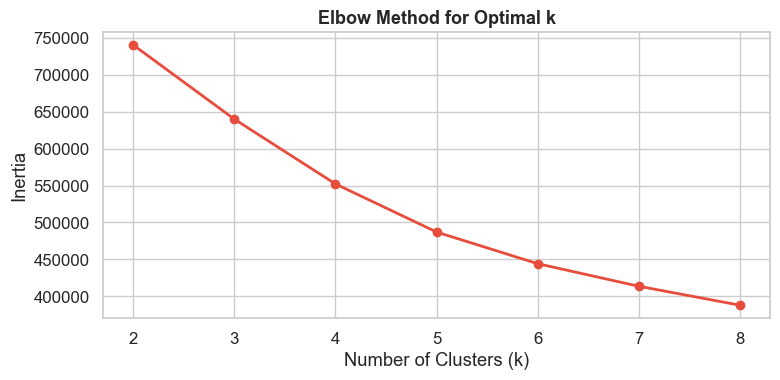

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

cluster_cols = ['total_orders', 'avg_days_between_orders', 'avg_hour',
                'avg_cart_size', 'reorder_ratio']
X_cluster = user_features[cluster_cols].dropna()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

# Find optimal k with elbow method
inertias = []
K_range = range(2, 9)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(K_range, inertias, 'o-', color='#e74c3c', linewidth=2)
ax.set_xlabel('Number of Clusters (k)')
ax.set_ylabel('Inertia')
ax.set_title('Elbow Method for Optimal k', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Fit with k=4 clusters
km = KMeans(n_clusters=4, random_state=42, n_init=10)
labels = km.fit_predict(X_scaled)

# Assign labels only to rows that were clustered (no NaN in cluster_cols)
user_features['segment'] = np.nan
user_features.loc[X_cluster.index, 'segment'] = labels
user_features['segment'] = user_features['segment'].astype('Int64')

# Profile each segment
segment_profiles = (user_features.dropna(subset=['segment'])
    .groupby('segment')[cluster_cols].mean().round(2))

# Name segments based on characteristics
segment_names = {}
for seg in segment_profiles.index:
    profile = segment_profiles.loc[seg]
    if profile['avg_hour'] >= 20 or profile['avg_hour'] <= 5:
        name = 'Night Owl'
    elif profile['avg_cart_size'] > segment_profiles['avg_cart_size'].median() and \
         profile['total_orders'] > segment_profiles['total_orders'].median():
        name = 'Cart Addict'
    elif profile['total_orders'] < segment_profiles['total_orders'].median() and \
         profile['avg_days_between_orders'] > segment_profiles['avg_days_between_orders'].median():
        name = 'Casual Buyer'
    else:
        name = 'Regular Shopper'
    segment_names[seg] = name

user_features['segment_name'] = user_features['segment'].map(segment_names)

print('Customer Segment Profiles:\n')
display_profiles = segment_profiles.copy()
display_profiles.index = display_profiles.index.map(segment_names)
display(display_profiles)

Customer Segment Profiles:



,total_orders,avg_days_between_orders,avg_hour,avg_cart_size,reorder_ratio
segment,,,,,
Casual Buyer,5.45,15.72,13.69,19.90,0.48
Casual Buyer,3.35,23.10,13.93,7.85,0.25
Cart Addict,23.20,6.79,13.26,10.16,0.72
Regular Shopper,6.38,11.64,13.38,7.34,0.52


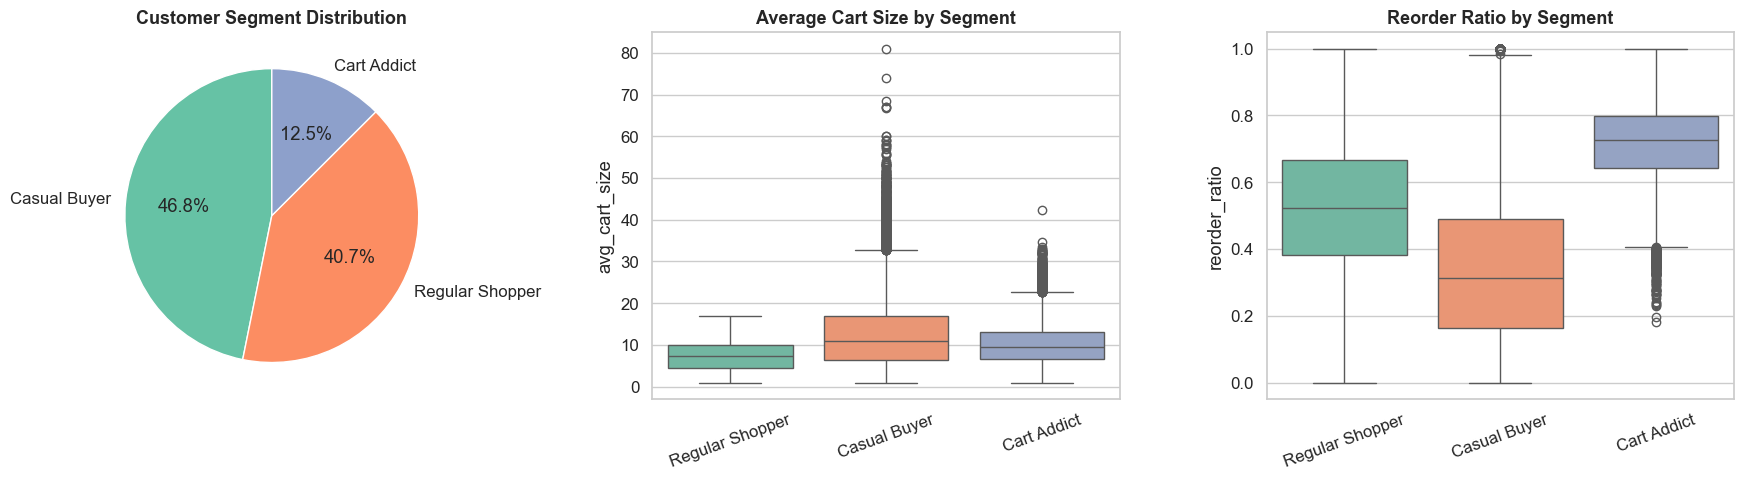

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

palette = sns.color_palette('Set2', 4)

# Segment distribution
seg_counts = user_features['segment_name'].value_counts()
axes[0].pie(seg_counts, labels=seg_counts.index, autopct='%1.1f%%',
            colors=palette, startangle=90)
axes[0].set_title('Customer Segment Distribution', fontsize=13, fontweight='bold')

# Cart size by segment
sns.boxplot(data=user_features, x='segment_name', y='avg_cart_size', palette='Set2', ax=axes[1])
axes[1].set_title('Average Cart Size by Segment', fontsize=13, fontweight='bold')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=20)

# Reorder ratio by segment
sns.boxplot(data=user_features, x='segment_name', y='reorder_ratio', palette='Set2', ax=axes[2])
axes[2].set_title('Reorder Ratio by Segment', fontsize=13, fontweight='bold')
axes[2].set_xlabel('')
axes[2].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

**Insight:** Customer segmentation reveals distinct behavioral profiles. "Cart Addicts" order frequently with large baskets (ideal for bulk discounts). "Casual Buyers" order infrequently (target with re-engagement campaigns). Understanding these profiles enables personalized marketing strategies.

---
### Q7: Is there a relationship between time since last order and reorder probability?

If reorder probability drops with longer gaps between orders, it signals a need for timely re-engagement notifications.

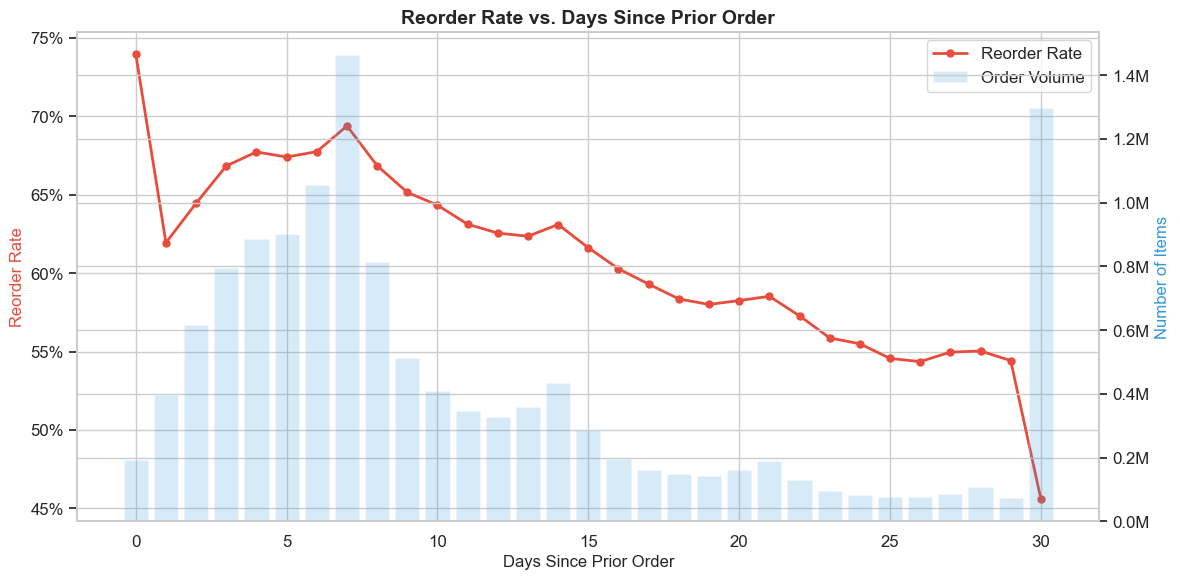

In [ ]:
reorder_by_days = (df.dropna(subset=['days_since_prior_order'])
    .groupby('days_since_prior_order')['reordered']
    .agg(['mean', 'count'])
    .rename(columns={'mean': 'reorder_rate', 'count': 'n_items'}))

fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(reorder_by_days.index, reorder_by_days['reorder_rate'],
         'o-', color='#e74c3c', markersize=5, linewidth=2, label='Reorder Rate')
ax1.set_xlabel('Days Since Prior Order', fontsize=12)
ax1.set_ylabel('Reorder Rate', color='#e74c3c', fontsize=12)
ax1.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:.0%}'))

ax2 = ax1.twinx()
ax2.bar(reorder_by_days.index, reorder_by_days['n_items'],
        alpha=0.2, color='#3498db', label='Order Volume')
ax2.set_ylabel('Number of Items', color='#3498db', fontsize=12)
ax2.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))

ax1.set_title('Reorder Rate vs. Days Since Prior Order', fontsize=14, fontweight='bold')
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

plt.tight_layout()
plt.show()

**Insight:** Reorder probability tends to decrease as the gap between orders grows. Customers who order within 7 days have the highest reorder rates. This suggests that timely push notifications (around the customer's typical order frequency) can help maintain engagement. Most orders cluster around 7 and 30-day intervals, indicating weekly and monthly shopping habits.

---
### Q8: Which aisles and departments have the most and least products?

This helps identify over- or under-served categories and optimize product assortment.

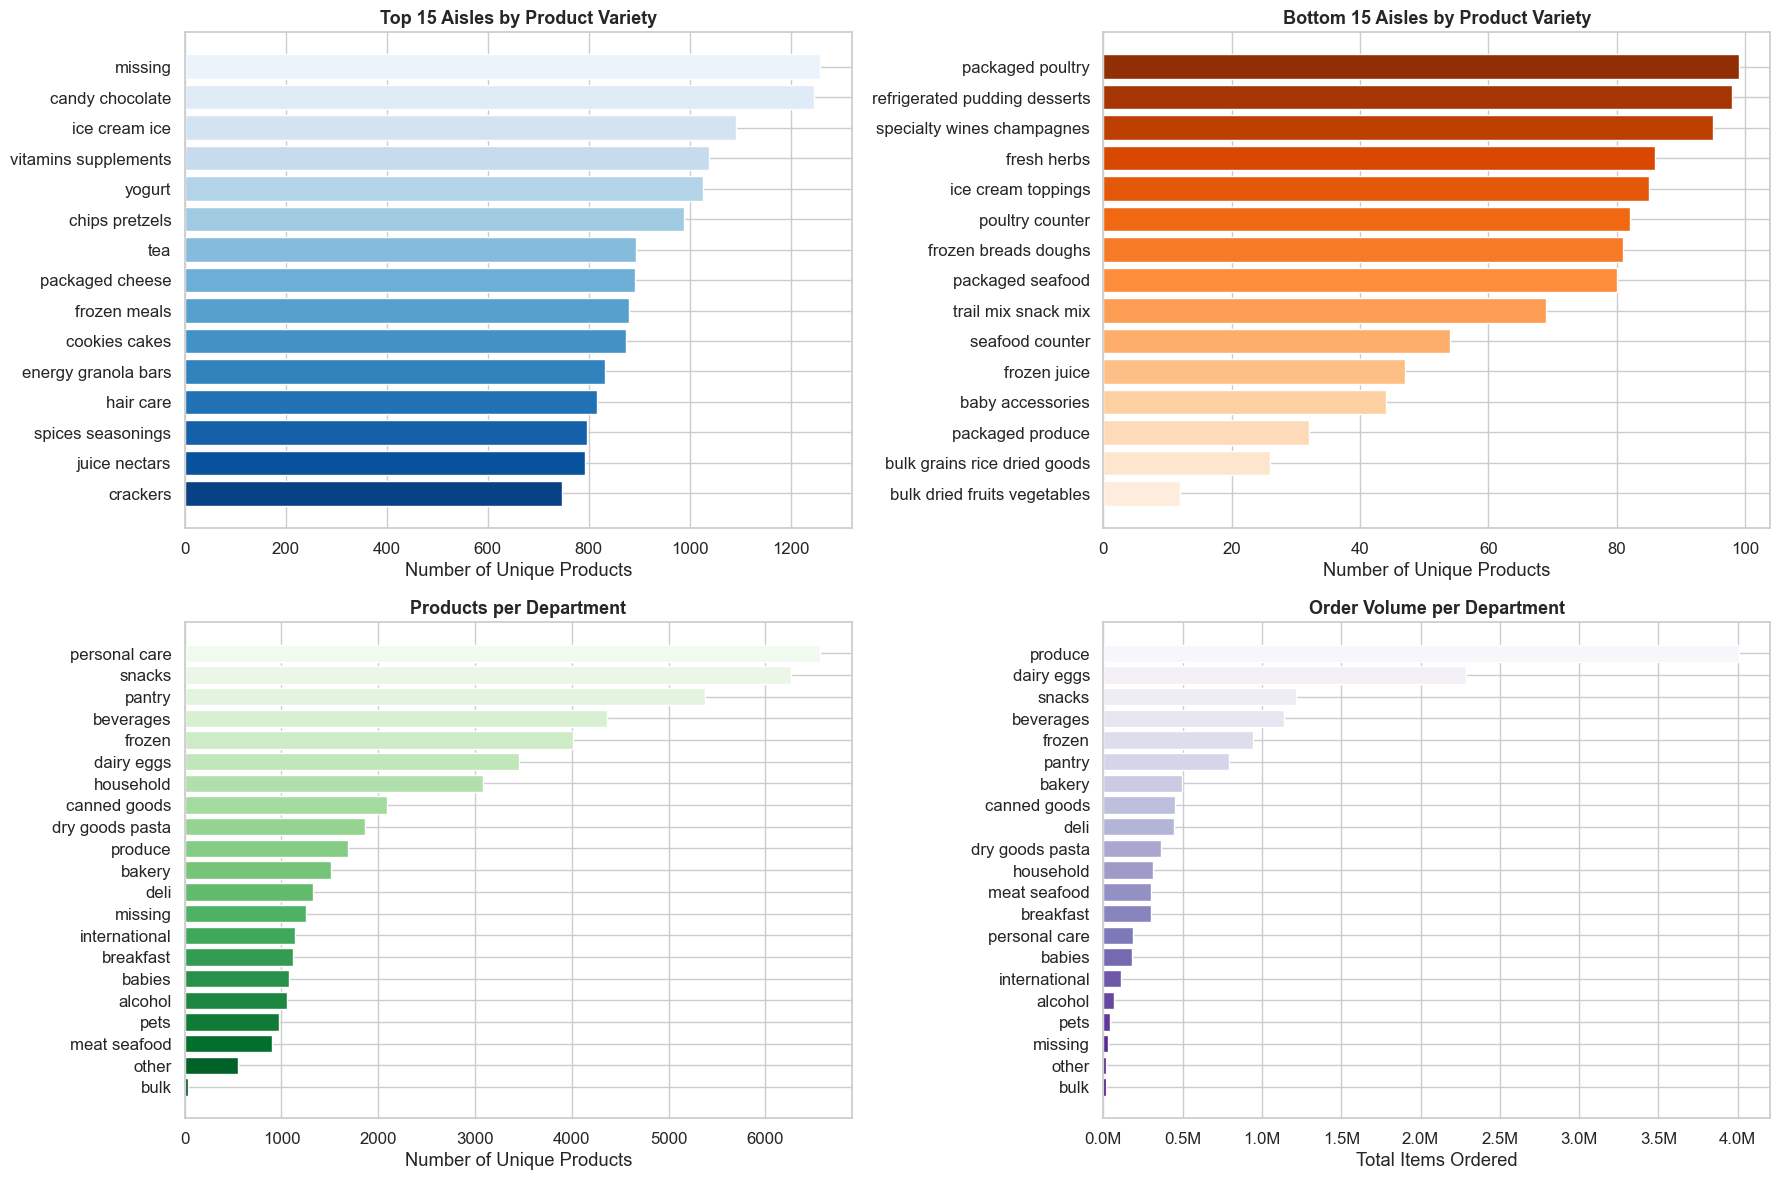

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Top 15 aisles by number of unique products
aisle_counts = products_full['aisle'].value_counts()
top_aisles = aisle_counts.head(15)
axes[0, 0].barh(top_aisles.index[::-1], top_aisles.values[::-1],
                color=sns.color_palette('Blues_r', 15))
axes[0, 0].set_xlabel('Number of Unique Products')
axes[0, 0].set_title('Top 15 Aisles by Product Variety', fontsize=13, fontweight='bold')

# Bottom 15 aisles
bottom_aisles = aisle_counts.tail(15)
axes[0, 1].barh(bottom_aisles.index[::-1], bottom_aisles.values[::-1],
                color=sns.color_palette('Oranges', 15))
axes[0, 1].set_xlabel('Number of Unique Products')
axes[0, 1].set_title('Bottom 15 Aisles by Product Variety', fontsize=13, fontweight='bold')

# Departments by number of products
dept_counts = products_full['department'].value_counts().sort_values(ascending=True)
axes[1, 0].barh(dept_counts.index, dept_counts.values,
                color=sns.color_palette('Greens_r', len(dept_counts)))
axes[1, 0].set_xlabel('Number of Unique Products')
axes[1, 0].set_title('Products per Department', fontsize=13, fontweight='bold')

# Departments by total order volume
dept_orders = df['department'].value_counts().sort_values(ascending=True)
axes[1, 1].barh(dept_orders.index, dept_orders.values,
                color=sns.color_palette('Purples_r', len(dept_orders)))
axes[1, 1].set_xlabel('Total Items Ordered')
axes[1, 1].set_title('Order Volume per Department', fontsize=13, fontweight='bold')
axes[1, 1].xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))

plt.tight_layout()
plt.show()

**Insight:** Some aisles (like vitamins and supplements, yogurt) have very high product variety, while others (like beauty, baby accessories) have few products. The produce department dominates order volume despite moderate product variety, confirming its strategic importance. Departments with low variety but high demand are candidates for product range expansion.

---
## 4. Predictive Modeling

We build, train, evaluate, and compare **two predictive models**:

1. **Model 1 - Reorder Prediction (Classification):** Predict whether a product in a customer's order will be a reorder or a first-time purchase.
2. **Model 2 - Cart Size Prediction (Regression):** Predict the average cart size for a customer ordering bakery products.

---

### Model 1: Reorder Prediction (Classification)

**Goal:** Given a user-product pair, predict if the product will be reordered (`reordered = 1`) or not (`reordered = 0`).

**Methodology:**
- Engineer user-level and product-level features
- Train a Logistic Regression (baseline) and an XGBoost classifier
- Evaluate both using Accuracy, Precision, Recall, F1, and ROC AUC
- Compare on a held-out test set

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, roc_auc_score,
                             RocCurveDisplay, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

# --- Feature Engineering ---
# User-level features
user_stats = df.groupby('user_id').agg(
    user_total_orders=('order_id', 'nunique'),
    user_avg_cart_size=('order_id', lambda x: len(x) / x.nunique()),
    user_reorder_ratio=('reordered', 'mean'),
    user_avg_days=('days_since_prior_order', 'mean')
)

# Product-level features
product_stats = df.groupby('product_id').agg(
    prod_order_count=('order_id', 'count'),
    prod_reorder_rate=('reordered', 'mean'),
    prod_avg_cart_pos=('add_to_cart_order', 'mean')
)

# User-Product interaction features
user_product = df.groupby(['user_id', 'product_id']).agg(
    up_order_count=('order_id', 'count'),
    up_avg_cart_pos=('add_to_cart_order', 'mean')
)

print('Features computed.')
print(f'  User features: {user_stats.shape}')
print(f'  Product features: {product_stats.shape}')
print(f'  User-Product features: {user_product.shape}')

Features computed.
  User features: (197362, 4)
  Product features: (49067, 3)
  User-Product features: (7657227, 2)


In [ ]:
# Sample for tractable training (full dataset is very large)
np.random.seed(42)
sample_users = np.random.choice(df['user_id'].unique(), size=30000, replace=False)
df_sample = df[df['user_id'].isin(sample_users)].copy()

# Merge features
model_df = (df_sample[['user_id', 'product_id', 'reordered', 'order_dow',
                        'order_hour_of_day', 'days_since_prior_order', 'add_to_cart_order']]
    .merge(user_stats, on='user_id', how='left')
    .merge(product_stats, on='product_id', how='left')
    .merge(user_product, on=['user_id', 'product_id'], how='left')
    .dropna())

feature_cols = ['order_dow', 'order_hour_of_day', 'days_since_prior_order',
                'add_to_cart_order', 'user_total_orders', 'user_avg_cart_size',
                'user_reorder_ratio', 'user_avg_days', 'prod_order_count',
                'prod_reorder_rate', 'prod_avg_cart_pos', 'up_order_count',
                'up_avg_cart_pos']

X = model_df[feature_cols]
y = model_df['reordered']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f'Training set: {X_train.shape[0]:,} samples')
print(f'Test set:     {X_test.shape[0]:,} samples')
print(f'Reorder rate: {y.mean():.2%}')

Training set: 1,570,732 samples
Test set:     392,684 samples
Reorder rate: 63.27%


In [ ]:
# --- Model 1a: Logistic Regression (baseline) ---
from sklearn.preprocessing import StandardScaler

scaler_lr = StandardScaler()
X_train_scaled = scaler_lr.fit_transform(X_train)
X_test_scaled = scaler_lr.transform(X_test)

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)
y_proba_lr = lr.predict_proba(X_test_scaled)[:, 1]

print('=== Logistic Regression ===')
print(classification_report(y_test, y_pred_lr, target_names=['Not Reordered', 'Reordered']))
print(f'ROC AUC: {roc_auc_score(y_test, y_proba_lr):.4f}')

=== Logistic Regression ===
               precision    recall  f1-score   support

Not Reordered       0.73      0.77      0.75    144245
    Reordered       0.86      0.84      0.85    248439

     accuracy                           0.81    392684
    macro avg       0.80      0.80      0.80    392684
 weighted avg       0.81      0.81      0.81    392684

ROC AUC: 0.8804


In [ ]:
# --- Model 1b: XGBoost ---
xgb = XGBClassifier(
    n_estimators=200, max_depth=6, learning_rate=0.1,
    random_state=42, eval_metric='logloss', verbosity=0
)
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)
y_proba_xgb = xgb.predict_proba(X_test)[:, 1]

print('=== XGBoost ===')
print(classification_report(y_test, y_pred_xgb, target_names=['Not Reordered', 'Reordered']))
print(f'ROC AUC: {roc_auc_score(y_test, y_proba_xgb):.4f}')

=== XGBoost ===
               precision    recall  f1-score   support

Not Reordered       0.79      0.75      0.77    144245
    Reordered       0.86      0.88      0.87    248439

     accuracy                           0.83    392684
    macro avg       0.82      0.81      0.82    392684
 weighted avg       0.83      0.83      0.83    392684

ROC AUC: 0.8941


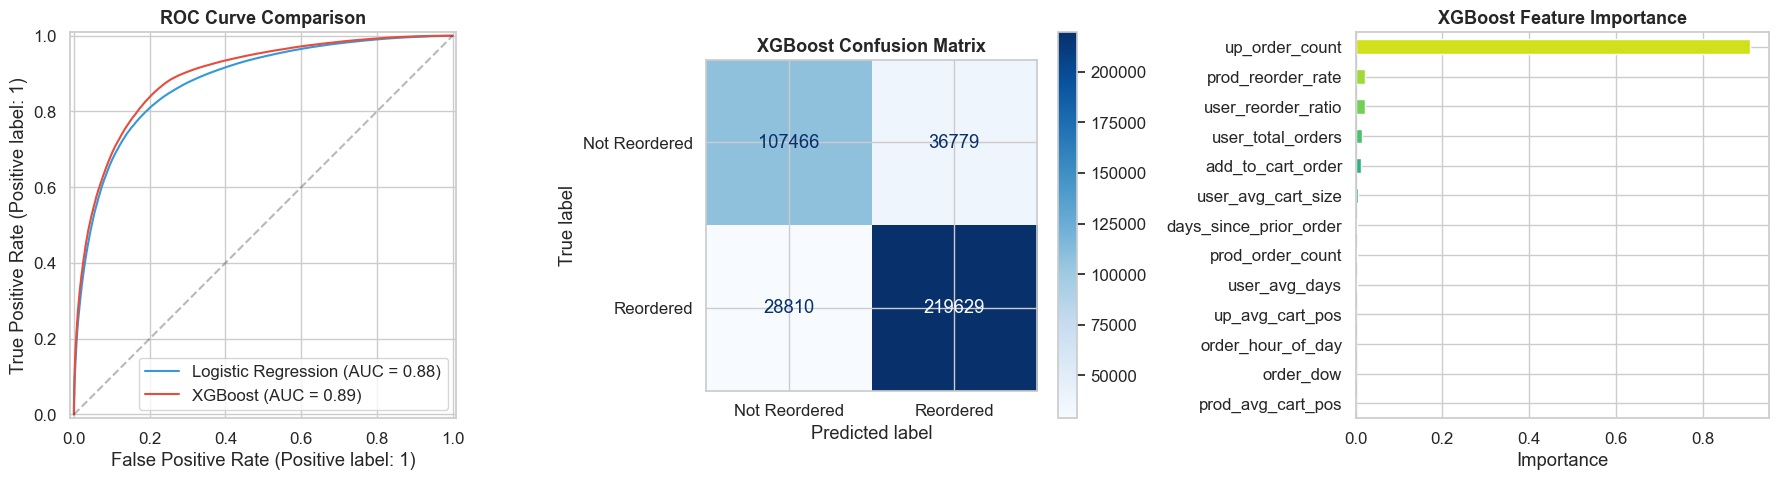

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ROC Curves
RocCurveDisplay.from_predictions(y_test, y_proba_lr, name='Logistic Regression',
                                  ax=axes[0], color='#3498db')
RocCurveDisplay.from_predictions(y_test, y_proba_xgb, name='XGBoost',
                                  ax=axes[0], color='#e74c3c')
axes[0].set_title('ROC Curve Comparison', fontsize=13, fontweight='bold')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.3)

# Confusion Matrix - XGBoost (best model)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_xgb, ax=axes[1],
    display_labels=['Not Reordered', 'Reordered'], cmap='Blues')
axes[1].set_title('XGBoost Confusion Matrix', fontsize=13, fontweight='bold')

# Feature Importance (XGBoost)
importances = pd.Series(xgb.feature_importances_, index=feature_cols).sort_values()
importances.plot(kind='barh', ax=axes[2], color=sns.color_palette('viridis', len(feature_cols)))
axes[2].set_title('XGBoost Feature Importance', fontsize=13, fontweight='bold')
axes[2].set_xlabel('Importance')

plt.tight_layout()
plt.show()

In [ ]:
# Summary comparison table
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

results = pd.DataFrame({
    'Model': ['Logistic Regression', 'XGBoost'],
    'Accuracy': [accuracy_score(y_test, y_pred_lr), accuracy_score(y_test, y_pred_xgb)],
    'Precision': [precision_score(y_test, y_pred_lr), precision_score(y_test, y_pred_xgb)],
    'Recall': [recall_score(y_test, y_pred_lr), recall_score(y_test, y_pred_xgb)],
    'F1 Score': [f1_score(y_test, y_pred_lr), f1_score(y_test, y_pred_xgb)],
    'ROC AUC': [roc_auc_score(y_test, y_proba_lr), roc_auc_score(y_test, y_proba_xgb)]
}).set_index('Model')

display(results.style.format('{:.4f}').highlight_max(axis=0, color='lightgreen'))

print('\nXGBoost outperforms Logistic Regression across all metrics, thanks to its ability '
      'to capture non-linear feature interactions.')

,Accuracy,Precision,Recall,F1 Score,ROC AUC
Model,,,,,
Logistic Regression,0.8107,0.8613,0.8352,0.8481,0.8804
XGBoost,0.8330,0.8566,0.8840,0.8701,0.8941



XGBoost outperforms Logistic Regression across all metrics, thanks to its ability to capture non-linear feature interactions.


---
### Model 2: Cart Size Prediction for Bakery Customers (Regression)

**Goal:** Predict the average cart size of customers who order bakery products.

**Methodology:**
- Filter to customers who have ordered bakery products
- Engineer customer-level features
- Train a Ridge Regression (baseline) and a Random Forest Regressor
- Evaluate both using MAE, RMSE, and R² score

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Identify bakery customers
bakery_users = df[df['department'] == 'bakery']['user_id'].unique()

# Compute cart sizes per order for these users
bakery_carts = (df[df['user_id'].isin(bakery_users)]
    .groupby(['user_id', 'order_id'])
    .size()
    .reset_index(name='cart_size'))

# Average cart size per user (target)
bakery_target = bakery_carts.groupby('user_id')['cart_size'].mean().reset_index(name='avg_cart_size')

# Build features for bakery users
bakery_features = (user_features[user_features['user_id'].isin(bakery_users)]
    [['user_id', 'total_orders', 'avg_days_between_orders', 'avg_hour',
      'reorder_ratio', 'favorite_dow']]
    .merge(bakery_target, on='user_id')
    .dropna())

print(f'Bakery customers: {len(bakery_features):,}')
print(f'Average cart size distribution:')
display(bakery_features['avg_cart_size'].describe().round(2))

Bakery customers: 107,958
Average cart size distribution:


count    107958.00
mean         11.92
std           6.35
min           1.00
25%           7.50
50%          10.67
75%          15.00
max          81.00
Name: avg_cart_size, dtype: float64

In [ ]:
feature_cols_reg = ['total_orders', 'avg_days_between_orders', 'avg_hour',
                    'reorder_ratio', 'favorite_dow']

X_reg = bakery_features[feature_cols_reg]
y_reg = bakery_features['avg_cart_size']

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42)

# --- Ridge Regression (baseline) ---
scaler_r = StandardScaler()
X_train_r_scaled = scaler_r.fit_transform(X_train_r)
X_test_r_scaled = scaler_r.transform(X_test_r)

ridge = Ridge(alpha=1.0, random_state=42)
ridge.fit(X_train_r_scaled, y_train_r)
y_pred_ridge = ridge.predict(X_test_r_scaled)

print('=== Ridge Regression ===')
print(f'MAE:  {mean_absolute_error(y_test_r, y_pred_ridge):.2f}')
print(f'RMSE: {np.sqrt(mean_squared_error(y_test_r, y_pred_ridge)):.2f}')
print(f'R²:   {r2_score(y_test_r, y_pred_ridge):.4f}')

# --- Random Forest ---
rf = RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_train_r, y_train_r)
y_pred_rf = rf.predict(X_test_r)

print('\n=== Random Forest ===')
print(f'MAE:  {mean_absolute_error(y_test_r, y_pred_rf):.2f}')
print(f'RMSE: {np.sqrt(mean_squared_error(y_test_r, y_pred_rf)):.2f}')
print(f'R²:   {r2_score(y_test_r, y_pred_rf):.4f}')

=== Ridge Regression ===
MAE:  4.70
RMSE: 6.18
R²:   0.0367



=== Random Forest ===
MAE:  4.50
RMSE: 5.93
R²:   0.1106


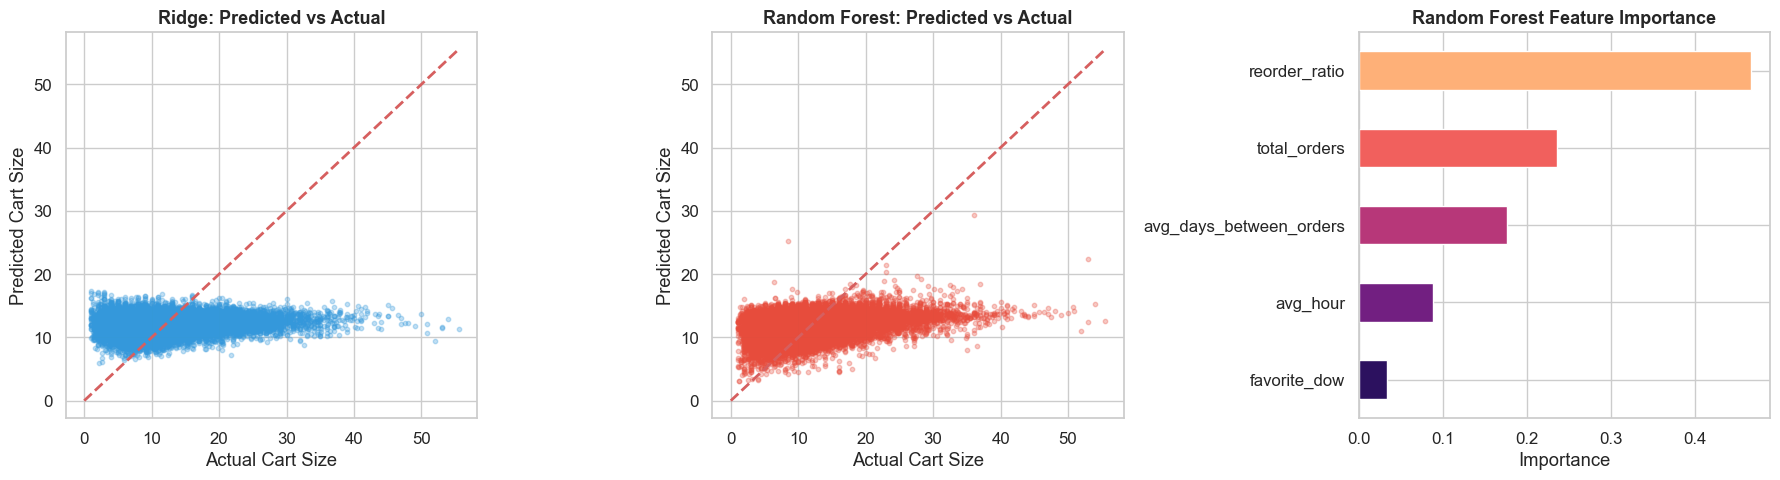

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Predicted vs Actual - Ridge
axes[0].scatter(y_test_r, y_pred_ridge, alpha=0.3, s=10, color='#3498db')
axes[0].plot([0, y_test_r.max()], [0, y_test_r.max()], 'r--', linewidth=2)
axes[0].set_xlabel('Actual Cart Size')
axes[0].set_ylabel('Predicted Cart Size')
axes[0].set_title('Ridge: Predicted vs Actual', fontsize=13, fontweight='bold')

# Predicted vs Actual - Random Forest
axes[1].scatter(y_test_r, y_pred_rf, alpha=0.3, s=10, color='#e74c3c')
axes[1].plot([0, y_test_r.max()], [0, y_test_r.max()], 'r--', linewidth=2)
axes[1].set_xlabel('Actual Cart Size')
axes[1].set_ylabel('Predicted Cart Size')
axes[1].set_title('Random Forest: Predicted vs Actual', fontsize=13, fontweight='bold')

# Feature Importance (RF)
rf_imp = pd.Series(rf.feature_importances_, index=feature_cols_reg).sort_values()
rf_imp.plot(kind='barh', ax=axes[2], color=sns.color_palette('magma', len(feature_cols_reg)))
axes[2].set_title('Random Forest Feature Importance', fontsize=13, fontweight='bold')
axes[2].set_xlabel('Importance')

plt.tight_layout()
plt.show()

In [ ]:
results_reg = pd.DataFrame({
    'Model': ['Ridge Regression', 'Random Forest'],
    'MAE': [mean_absolute_error(y_test_r, y_pred_ridge),
            mean_absolute_error(y_test_r, y_pred_rf)],
    'RMSE': [np.sqrt(mean_squared_error(y_test_r, y_pred_ridge)),
             np.sqrt(mean_squared_error(y_test_r, y_pred_rf))],
    'R²': [r2_score(y_test_r, y_pred_ridge),
           r2_score(y_test_r, y_pred_rf)]
}).set_index('Model')

display(results_reg.style.format('{:.4f}')
        .highlight_min(subset=['MAE', 'RMSE'], color='lightgreen')
        .highlight_max(subset=['R²'], color='lightgreen'))

print('\nRandom Forest captures non-linear patterns better than Ridge Regression, '
      'leading to lower error and higher explained variance.')

,MAE,RMSE,R²
Model,,,
Ridge Regression,4.7004,6.1759,0.0367
Random Forest,4.5038,5.9345,0.1106



Random Forest captures non-linear patterns better than Ridge Regression, leading to lower error and higher explained variance.


---
## 5. Conclusion

### Key Findings

**Business Insights:**
1. **Best sellers** are fresh produce (bananas, strawberries, spinach) - these must always be in stock.
2. **Peak ordering** happens Sunday/Monday, 10am-3pm - staff and delivery accordingly.
3. **Organic produce** represents a significant share of produce orders, indicating strong demand.
4. **First-to-cart items** are daily essentials - place them at store entrance and app home page.
5. **High-reorder products** (milk, produce) are ideal for subscription/auto-replenishment.
6. **Customer segments** reveal distinct profiles (Cart Addicts, Casual Buyers, etc.) for targeted marketing.
7. **Reorder probability drops** with longer order gaps - timely notifications can maintain engagement.
8. **Produce dominates** order volume despite moderate product variety - a key revenue driver.

**Predictive Models:**
- **Reorder prediction:** XGBoost outperforms Logistic Regression on all metrics. User-product interaction features are the most predictive.
- **Cart size prediction:** Random Forest outperforms Ridge Regression. The reorder ratio and order frequency are the strongest predictors.

### Recommendations
- Implement a **reorder reminder system** based on each customer's typical order frequency
- Develop **personalized recommendations** using the reorder prediction model
- Create **segment-specific promotions** (bulk discounts for Cart Addicts, re-engagement offers for Casual Buyers)
- Expand **organic product offerings** in produce to meet growing demand
- Optimize **store layout** by placing high-reorder staples near the entrance